# Solvers: Forward Euler, Backward Euler and RK4

This notebook is the solver part of the project and continues the Models notebook.
Here we compute the whole solution from $t = 0$ to $t = T$ with three methods, Forward Euler, Backward Euler and RK4, and look at how the error changes with the number of steps.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. The models from the Models notebook

The cells below are copied from the Models notebook without change: the example parameters and the dictionary `params`, four functions of each model, `rhs`, `exact`, `be_step` and `dfdV`, and the `MODELS` dictionary.

In [2]:
V0 = 1.0
T = 60.0
plateau = 10.0

a_L = 0.2 / (1 - V0 / plateau)
p_L = {"a_L": a_L, "K": plateau}

a_G = 0.2
beta = a_G / np.log(plateau / V0)
p_G = {"a_G": a_G, "beta": beta}

params = {"logistic": p_L, "gompertz": p_G}

print("p_L =", p_L)
print("p_G =", p_G)

p_L = {'a_L': 0.22222222222222224, 'K': 10.0}
p_G = {'a_G': 0.2, 'beta': np.float64(0.08685889638065036)}


In [3]:
def logistic_rhs(t, V, p):
    a_L = p["a_L"]
    K = p["K"]
    return a_L * V * (1 - V / K)


def logistic_exact(t, V0, p):
    a_L = p["a_L"]
    K = p["K"]
    return K / (1 + (K / V0 - 1) * np.exp(-a_L * t))


def gompertz_rhs(t, V, p):
    a_G = p["a_G"]
    beta = p["beta"]
    return a_G * np.exp(-beta * t) * V


def gompertz_exact(t, V0, p):
    a_G = p["a_G"]
    beta = p["beta"]
    return V0 * np.exp(a_G / beta * (1 - np.exp(-beta * t)))


def logistic_be_step(t_next, V_prev, h, p):
    a_L = p["a_L"]
    K = p["K"]
    c = h * a_L / K
    B = 1 - h * a_L
    D = B**2 + 4 * c * V_prev
    return (-B + np.sqrt(D)) / (2 * c)


def gompertz_be_step(t_next, V_prev, h, p):
    a_G = p["a_G"]
    beta = p["beta"]
    denom = 1 - h * a_G * np.exp(-beta * t_next)
    if denom <= 0:
        return np.nan
    return V_prev / denom


def logistic_dfdV(t, V, p):
    a_L = p["a_L"]
    K = p["K"]
    return a_L * (1 - 2 * V / K)


def gompertz_dfdV(t, V, p):
    a_G = p["a_G"]
    beta = p["beta"]
    return a_G * np.exp(-beta * t)

In [4]:
MODELS = {
    "logistic": {
        "rhs": logistic_rhs,
        "exact": logistic_exact,
        "be_step": logistic_be_step,
        "dfdV": logistic_dfdV,
    },
    "gompertz": {
        "rhs": gompertz_rhs,
        "exact": gompertz_exact,
        "be_step": gompertz_be_step,
        "dfdV": gompertz_dfdV,
    },
}

## 2. The grid and the common call

### 2.1 The grid

In the Models notebook we just chose one step size $h$ and the grid times $t_n = n h$.
Now we want the whole interval $[0, T]$, so we choose the number of steps $N$ and divide $[0, T]$ into $N$ equal steps:

$$h = \frac{T}{N}, \qquad t_n = n\, h, \qquad n = 0, 1, \ldots, N$$

So $t_0 = 0$ and $t_N = N h = T$. We have $N + 1$ grid points.
These method starts from the known $V_0$ and computes $V_1, \ldots, V_N$, one per step. So the loop in the code runs $N$ times.

In code the grid is `t = np.linspace(0, T, N + 1)`, which gives $N + 1$ evenly spaced numbers from $0$ to $T$, both ends included. The step size is `h = T / N`.

All three methods use the same grid. So for the same $N$ their results are at the same times and can be compared point by point.

### 2.2 The common call

Every method in this notebook is a function with the same arguments and the same output:

f(model, p, V0, T, N)   ->  (t, V)

| Argument | Meaning |
|---|---|
| `model` | One entry of `MODELS`, e.g. `MODELS["gompertz"]` |
| `p` | The parameter dictionary of the model. |
| `V0`, `T`, `N` | Starting volume, final time, number of steps |

The output `t` is the grid above, and `V` is an array of length $N + 1$ with `V[n]` $= V_n$.
The method creates it with `V = np.zeros(N + 1)`, sets `V[0] = V0`, and then fills in `V[1]`, ..., `V[N]` one step at a time.

Everything that belongs to a model comes from `model` and `p`.
So the same method runs on both models, which is what the `MODELS` dictionary of the Models notebook was built for.

## 3. Forward Euler

### 3.1 Formula

Forward Euler uses the slope at the start of each step:

$$V_{n+1} = V_n + h\, f(t_n, V_n), \qquad n = 0, 1, \ldots, N - 1$$

Everything on the right is known, so each step is just one evaluation of $f$.
The slope is taken at the start time $t_n$, so step $n$ passes `t[n]` to `rhs`.

### 3.2 Code: `forward_euler`

The line inside the loop is the formula above, with $V_n$ (`V[n]`) and $t_n$ (`t[n]`).

In [5]:
def forward_euler(model, p, V0, T, N):
    rhs = model["rhs"]
    t = np.linspace(0, T, N + 1)
    h = T / N
    V = np.zeros(N + 1)
    V[0] = V0
    for n in range(N):
        V[n + 1] = V[n] + h * rhs(t[n], V[n], p)
    return t, V

### 3.3 Picture: Forward Euler and the exact solution

We will draw the same picture for every method, so we put the plotting code into a function `plot_against_exact(method, method_label)`.
It draws the exact solution and the method with $N = 16$ and $N = 64$; Logistic on the left, Gompertz on the right.

With $N = 64$ the points lie closer to the exact curve than with $N = 16$.

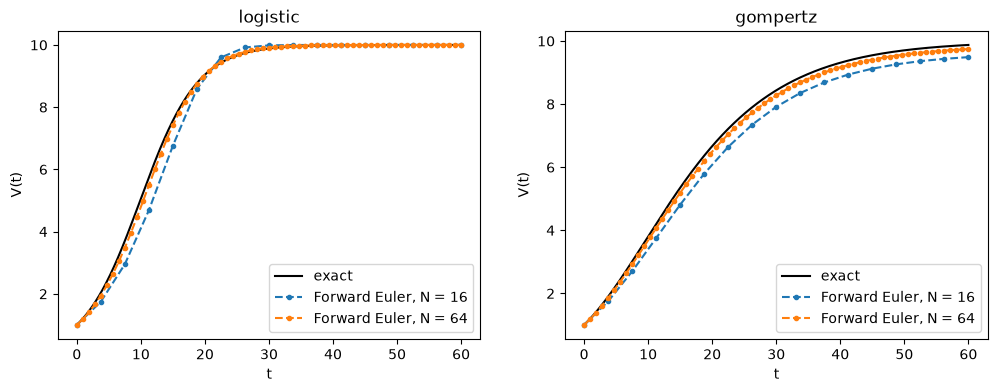

In [6]:
def plot_against_exact(method, method_label):
    t_plot = np.linspace(0, T, 601)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, model_name in zip(axes, ["logistic", "gompertz"]):
        model = MODELS[model_name]
        p = params[model_name]
        ax.plot(t_plot, model["exact"](t_plot, V0, p), color="black", label="exact")
        for N in [16, 64]:
            t, V = method(model, p, V0, T, N)
            ax.plot(t, V, "o--", markersize=3, label=method_label + ", N = " + str(N))
        ax.set_xlabel("t")
        ax.set_ylabel("V(t)")
        ax.set_title(model_name)
        ax.legend()
    plt.show()


plot_against_exact(forward_euler, "Forward Euler")

## 4. Backward Euler

### 4.1 Formula

Backward Euler uses the slope at the end of each step:

$$V_{n+1} = V_n + h\, f(t_{n+1}, V_{n+1}), \qquad n = 0, 1, \ldots, N - 1$$

The unknown $V_{n+1}$ appears on both sides, so each step is an equation that has to be solved for $V_{n+1}$ (implicit).

### 4.2 Solve the equation

In the Models notebook we solved this equation by hand for both models (a quadratic for Logistic, a linear equation for Gompertz).
The result is the function `be_step(t_next, V_prev, h, p)` of each model, which returns $V_{n+1}$.
So the method calls `model["be_step"]` once per step and does not call `rhs`.
The slope is taken at the end of the step, so step $n$ passes `t[n + 1]` as `t_next`.

### 4.3 When a step fails

The Gompertz `be_step` returns `np.nan` when the step has no valid result.
Every later step would start from that invalid value, so the method sets this step and all later values to `nan` and stops the loop.

### 4.4 Code: `backward_euler`

In [7]:
def backward_euler(model, p, V0, T, N):
    be_step = model["be_step"]
    t = np.linspace(0, T, N + 1)
    h = T / N
    V = np.zeros(N + 1)
    V[0] = V0
    for n in range(N):
        V[n + 1] = be_step(t[n + 1], V[n], h, p)
        if np.isnan(V[n + 1]):
            V[n + 1:] = np.nan
            break
    return t, V

### 4.5 Picture: Backward Euler and the exact solution

Again the points with $N = 64$ lie closer to the exact curve than with $N = 16$.

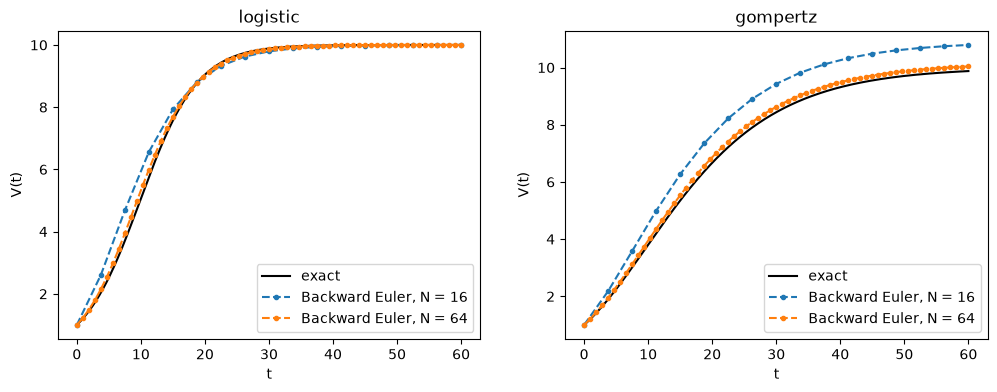

In [8]:
plot_against_exact(backward_euler, "Backward Euler")

## 5. RK4

### 5.1 Formula

The classical Runge–Kutta method of order 4 (RK4) takes four slopes in each step and uses a weighted average of them:

$$
\begin{aligned}
k_1 &= f(t_n,\; V_n) \\
k_2 &= f\!\left(t_n + \tfrac{h}{2},\; V_n + \tfrac{h}{2} k_1\right) \\
k_3 &= f\!\left(t_n + \tfrac{h}{2},\; V_n + \tfrac{h}{2} k_2\right) \\
k_4 &= f\!\left(t_n + h,\; V_n + h\, k_3\right) \\
V_{n+1} &= V_n + \tfrac{h}{6}\left(k_1 + 2 k_2 + 2 k_3 + k_4\right)
\end{aligned}
$$

Each $k$ uses only $V_n$ and the $k$ before it, so it is explicit.
One step evaluates $f$ four times.

### 5.2 The four slopes

- **$k_1$**: the slope at the start of the step. This is the slope Forward Euler uses.
- **$k_2$**: go half a step with $k_1$ to the midpoint $t_n + h/2$.
- **$k_3$**: go half a step again, now with the midpoint slope $k_2$ instead of $k_1$.
- **$k_4$**: go a full step with $k_3$ to the end $t_n + h$.

The weights are $1 : 2 : 2 : 1$ out of $6$.

### 5.3 Each slope uses its own time

$k_1$ is taken at $t_n$, $k_2$ and $k_3$ at $t_n + h/2$, and $k_4$ at $t_n + h$.
For the Logistic model $f$ does not contain $t$, so a wrong time would not change anything.
For the Gompertz model $f = a_G e^{-\beta t} V$ contains $t$, so a wrong time gives a wrong slope and a wrong result.
So the code passes `t[n] + h / 2` and `t[n] + h` to `rhs`, not `t[n]` for all four slopes.

### 5.4 Code: `rk4`

In [9]:
def rk4(model, p, V0, T, N):
    rhs = model["rhs"]
    t = np.linspace(0, T, N + 1)
    h = T / N
    V = np.zeros(N + 1)
    V[0] = V0
    for n in range(N):
        k1 = rhs(t[n], V[n], p)
        k2 = rhs(t[n] + h / 2, V[n] + h / 2 * k1, p)
        k3 = rhs(t[n] + h / 2, V[n] + h / 2 * k2, p)
        k4 = rhs(t[n] + h, V[n] + h * k3, p)
        V[n + 1] = V[n] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, V

### 5.5 Picture: RK4 and the exact solution

Both RK4 runs lie on the exact curve, so the $N = 16$ points are hidden under the $N = 64$ points. How small the error really is, we measure below.

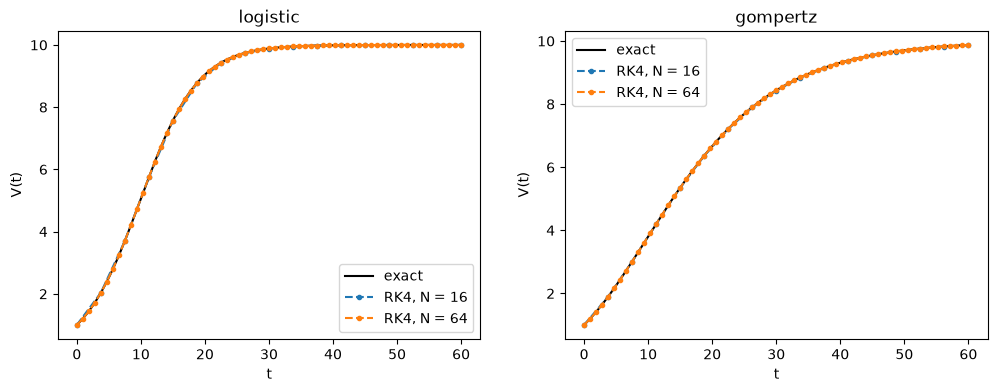

In [10]:
plot_against_exact(rk4, "RK4")

## 6. The `METHODS` dictionary

### 6.1 Idea

The three methods take the same arguments and return the same output.
So, as with `MODELS`, we put them into one dictionary: `METHODS["rk4"]` is the function `rk4`, and so on.
Then one loop over `MODELS` and one loop over `METHODS` run every method on every model, with no `if` for a particular model or method.

### 6.2 Code

In [11]:
METHODS = {
    "forward_euler": forward_euler,
    "backward_euler": backward_euler,
    "rk4": rk4,
}

In [12]:
N = 16

for model_name, model in MODELS.items():
    p = params[model_name]
    print(model_name, "exact:", round(model["exact"](T, V0, p), 6))
    for method_name, method in METHODS.items():
        t, V = method(model, p, V0, T, N)
        print(model_name, method_name + ":", round(V[-1], 6))

logistic exact: 9.999854
logistic forward_euler: 10.0
logistic backward_euler: 9.998373
logistic rk4: 9.999843
gompertz exact: 9.875218
gompertz forward_euler: 9.488628
gompertz backward_euler: 10.788697
gompertz rk4: 9.867577


### 6.3 Picture: the three methods together

The three methods with $N = 16$ and the exact solution, drawn with a loop over `METHODS`.
With the same $N$, RK4 is much closer to the exact curve than the two Euler methods.

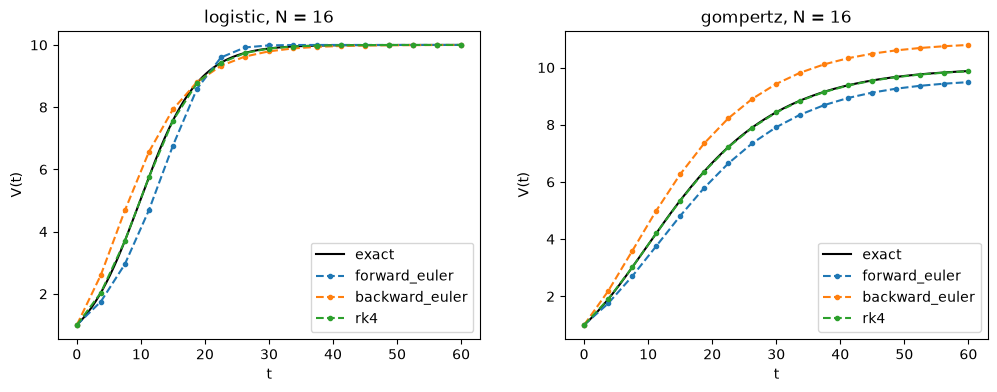

In [13]:
N = 16
t_plot = np.linspace(0, T, 601)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, model_name in zip(axes, ["logistic", "gompertz"]):
    model = MODELS[model_name]
    p = params[model_name]
    ax.plot(t_plot, model["exact"](t_plot, V0, p), color="black", label="exact")
    for method_name, method in METHODS.items():
        t, V = method(model, p, V0, T, N)
        ax.plot(t, V, "o--", markersize=3, label=method_name)
    ax.set_xlabel("t")
    ax.set_ylabel("V(t)")
    ax.set_title(model_name + ", N = 16")
    ax.legend()
plt.show()

## 7. How the error changes with $N$

### 7.1 Measuring the error

For one run we take the largest difference between the computed values and the exact solution on the grid, and divide it by the largest value of the exact solution, so that $E$ is relative to the size of the volume:

$$E = \frac{\max_n \lvert V_n - V(t_n) \rvert}{\max_n \lvert V(t_n) \rvert}$$

We take the largest error over the whole grid, not only the error at the final time, because the Logistic solution is close to its plateau at $T = 60$ and the error there is much smaller than earlier on. Since the exact solution increases, the divisor is $V(T)$ for every $N$, so it does not change the ratios below; it only makes $E$ free of units.


In the code, `V` holds $V_n$ and `V_exact` holds $V(t_n)$.

In [14]:
def max_rel_error(V, V_exact):
    return np.max(np.abs(V - V_exact)) / np.max(np.abs(V_exact))


t, V = forward_euler(MODELS["logistic"], p_L, V0, T, 16)
print("Forward Euler, logistic, N = 16:  E =", max_rel_error(V, logistic_exact(t, V0, p_L)))

Forward Euler, logistic, N = 16:  E = 0.10639071267929802


### 7.2 What we expect

Suppose the error behaves like $E \approx C h^p$ for small $h$, with a constant $C$ that does not depend on $h$. The number $p$ is the **order** of the method.
Doubling $N$ halves $h$, and then

$$\frac{E(h)}{E(h/2)} \approx \frac{C h^p}{C (h/2)^p} = 2^p, \qquad \text{so} \qquad p \approx \log_2 \frac{E(h)}{E(h/2)}$$

**Forward Euler and Backward Euler are first order.** The Taylor expansion of the exact solution at $t_n$ is

$$V(t_n + h) = V(t_n) + h\, V'(t_n) + \frac{h^2}{2} V''(t_n) + \ldots$$

Since $V'(t_n) = f(t_n, V(t_n))$, Forward Euler keeps the first two terms.
So one step that starts from the exact value makes an error of about $\frac{h^2}{2} V''$, which is proportional to $h^2$.
Going from $0$ to $T$ takes $N = T/h$ steps, and the errors of all the steps add up to something proportional to $N \cdot h^2 = T h$. So $E$ is proportional to $h$: $p = 1$.
For Backward Euler the same argument works with the Taylor expansion at $t_{n+1}$.

**RK4 is fourth order.** In the simple case where $f$ depends only on $t$, we have $k_2 = k_3 = f(t_n + h/2)$, and one RK4 step becomes

$$V_{n+1} = V_n + \frac{h}{6}\left(f(t_n) + 4 f\!\left(t_n + \tfrac{h}{2}\right) + f(t_n + h)\right)$$

This is Simpson's rule for $\int_{t_n}^{t_n + h} f(t)\, dt$, and Simpson's rule makes an error proportional to $h^5$ on one interval.
For a general $f(t, V)$ one can show the same: one step makes an error proportional to $h^5$ (we do not show this here).
After $N = T/h$ steps the error is proportional to $h^5 / h = h^4$: $p = 4$.

### 7.3 Table: the error for $N = 16, 32, \ldots, 1024$

For every model and every method we compute $E$ for these $N$ and store the errors in `errors[model_name][method_name]`.
We print $E$, the ratio $E(h)/E(h/2)$ from each $N$ to the next, and $p = \log_2$ of that ratio.
We expect ratios near 2 and $p$ near 1 for Forward Euler and Backward Euler, and ratios near 16 and $p$ near 4 for RK4.

In [15]:
np.set_printoptions(precision=3)
N_list = [16, 32, 64, 128, 256, 512, 1024]
errors = {}

for model_name, model in MODELS.items():
    p = params[model_name]
    errors[model_name] = {}
    for method_name, method in METHODS.items():
        E_list = []
        for N in N_list:
            t, V = method(model, p, V0, T, N)
            E_list.append(max_rel_error(V, model["exact"](t, V0, p)))
        errors[model_name][method_name] = E_list

        E = np.array(E_list)
        ratio = E[:-1] / E[1:]
        print(model_name, method_name)
        print("  E     =", E)
        print("  ratio =", ratio)
        print("  p     =", np.log2(ratio))

logistic forward_euler
  E     = [0.106 0.053 0.027 0.013 0.007 0.003 0.002]
  ratio = [1.996 1.993 2.006 2.001 2.001 2.001]
  p     = [0.997 0.995 1.005 1.001 1.001 1.001]
logistic backward_euler
  E     = [0.098 0.052 0.026 0.013 0.007 0.003 0.002]
  ratio = [1.882 1.968 1.991 1.995 1.998 1.999]
  p     = [0.912 0.976 0.994 0.996 0.998 0.999]
logistic rk4
  E     = [4.460e-04 3.158e-05 2.150e-06 1.403e-07 8.965e-09 5.664e-10 3.560e-11]
  ratio = [14.121 14.692 15.322 15.651 15.827 15.913]
  p     = [3.82  3.877 3.938 3.968 3.984 3.992]
gompertz forward_euler
  E     = [0.058 0.033 0.017 0.009 0.005 0.002 0.001]
  ratio = [1.78  1.881 1.936 1.967 1.983 1.991]
  p     = [0.832 0.912 0.953 0.976 0.988 0.994]
gompertz backward_euler
  E     = [0.102 0.043 0.02  0.01  0.005 0.002 0.001]
  ratio = [2.369 2.161 2.074 2.036 2.018 2.009]
  p     = [1.244 1.112 1.053 1.026 1.013 1.006]
gompertz rk4
  E     = [7.738e-04 6.128e-05 4.268e-06 2.806e-07 1.796e-08 1.136e-09 7.143e-11]
  ratio = [12.

### 7.4 Picture: error against step size

We draw $E$ against $h = T/N$ with both axes on a logarithmic scale.
If $E = C h^p$, then $\log E = \log C + p \log h$, which is a straight line with slope $p$.
The gray lines have slope 1 (dashed) and slope 4 (dotted), for comparison.

On both models the Forward Euler and Backward Euler points lie along the slope 1 line and the RK4 points along the slope 4 line, as expected.

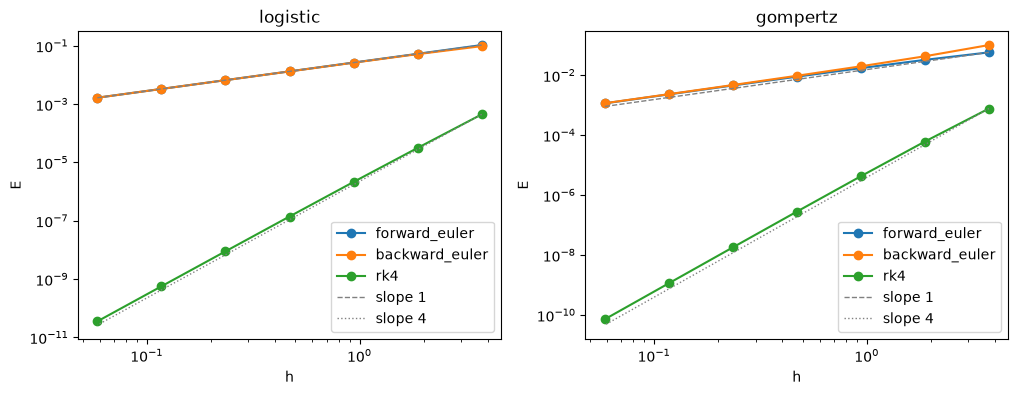

In [16]:
h_list = T / np.array(N_list)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, model_name in zip(axes, ["logistic", "gompertz"]):
    for method_name in METHODS:
        ax.loglog(h_list, errors[model_name][method_name], "o-", label=method_name)
    E_fe = errors[model_name]["forward_euler"]
    E_rk4 = errors[model_name]["rk4"]
    ax.loglog(h_list, E_fe[0] * (h_list / h_list[0]), color="gray", linestyle="--", linewidth=1, label="slope 1")
    ax.loglog(h_list, E_rk4[0] * (h_list / h_list[0])**4, color="gray", linestyle=":", linewidth=1, label="slope 4")
    ax.set_xlabel("h")
    ax.set_ylabel("E")
    ax.set_title(model_name)
    ax.legend()
plt.show()